In [16]:
import os, sys
sys.path.append(os.path.abspath("../bls_cuda"))  # bls_cuda is a git submodule of this repo

import numpy as np
import kbonus_data as kb         # KBonus light curve reader (pip install -e ..)

import matplotlib.pyplot as plt  #MatPlotLib for some simple plots 

# for BLS routine
import transitPy5 as tpy5        # routines to handle transit photometry
import bls_cpu as gbls           # BLS CPU implementation 

# Transit modelling module
import utils_python.transitmodel as transitm
import utils_python.keplerian as kep
import utils_python.transitfit as transitf
import utils_python.transitplot as transitp

In [70]:
# A KIC number (looked up under $KBONUS_DATA_DIR, else the current directory) or a path to a FITS file
target = "/opt/data2/rowe/test/hlsp_kbonus-bkg_kepler_kepler_kic-008311864_kepler_v1.1.1_lc.fits"
# target = 11904151

In [90]:
lc = kb.read_lightcurve(target)
print(lc.label, "-", len(lc), "cadences, quarters", lc.quarter.min(), "to", lc.quarter.max())

# Fill a bls_cuda phot object: time = BJD - 2454900, flux/ferr = SAP photometry
# (kind can be "sap", "psf" or "psf_flat")
phot = lc.to_phot(kind="sap", phot=tpy5.phot_class())

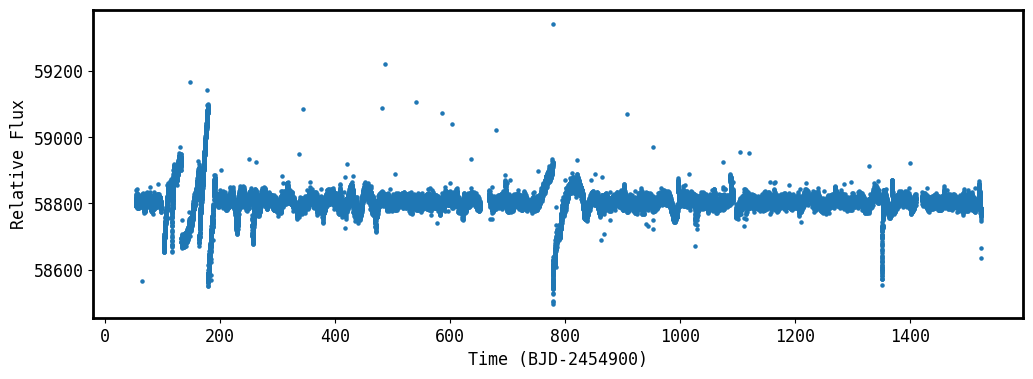

In [91]:
# Raw Light curve 
fig=plt.figure(figsize=(12, 4))
plt.rcParams.update({'font.size': 12})
plt.scatter(phot.time,phot.flux, s=5)
plt.xlabel('Time (BJD-2454900)')
plt.ylabel('Relative Flux')
plt.show()

# Run data processing (only use if fetching raw data)

Data conditioning for the transit search includes:
- applying a data filter
- rejecting outliers

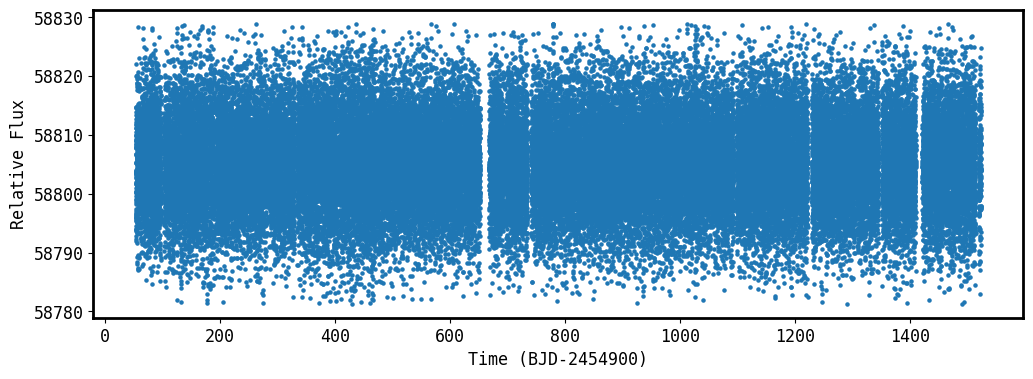

In [94]:
# Get default parameters
tpy5_inputs = tpy5.tpy5_inputs_class()

# Run the detrending and outlier detection (if needed) 
tpy5_inputs.boxbin = 2.0 # set detrending length
tpy5_inputs.nfitp  = 3   # Set polynomial order
tpy5.run_polyfilter(phot, tpy5_inputs)  # flux_f will contain the filtered photometry
tpy5.run_cutoutliers(phot, tpy5_inputs) # data clipping, phot.icut will flag bad data

# Do a simple 3-sigma cut 
med = np.median(phot.flux_f[(phot.icut==0) & (phot.time>200)])
std = np.std(phot.flux_f[(phot.icut==0) & (phot.time>200)])
med_cut = np.zeros((phot.time.shape[0]))
med_cut[np.abs(phot.flux_f - med) > 3.0 * std] = 1

# Processed Light curve 
fig=plt.figure(figsize=(12, 4))
plt.rcParams.update({'font.size': 12})
plt.scatter(phot.time[(phot.icut==0) & (med_cut==0)],phot.flux_f[(phot.icut==0) & (med_cut==0)], s=5)
# plt.scatter(phot.time[phot.icut==0],phot.flux_f[phot.icut==0], s=5)
plt.xlabel('Time (BJD-2454900)')
plt.ylabel('Relative Flux')
plt.show()

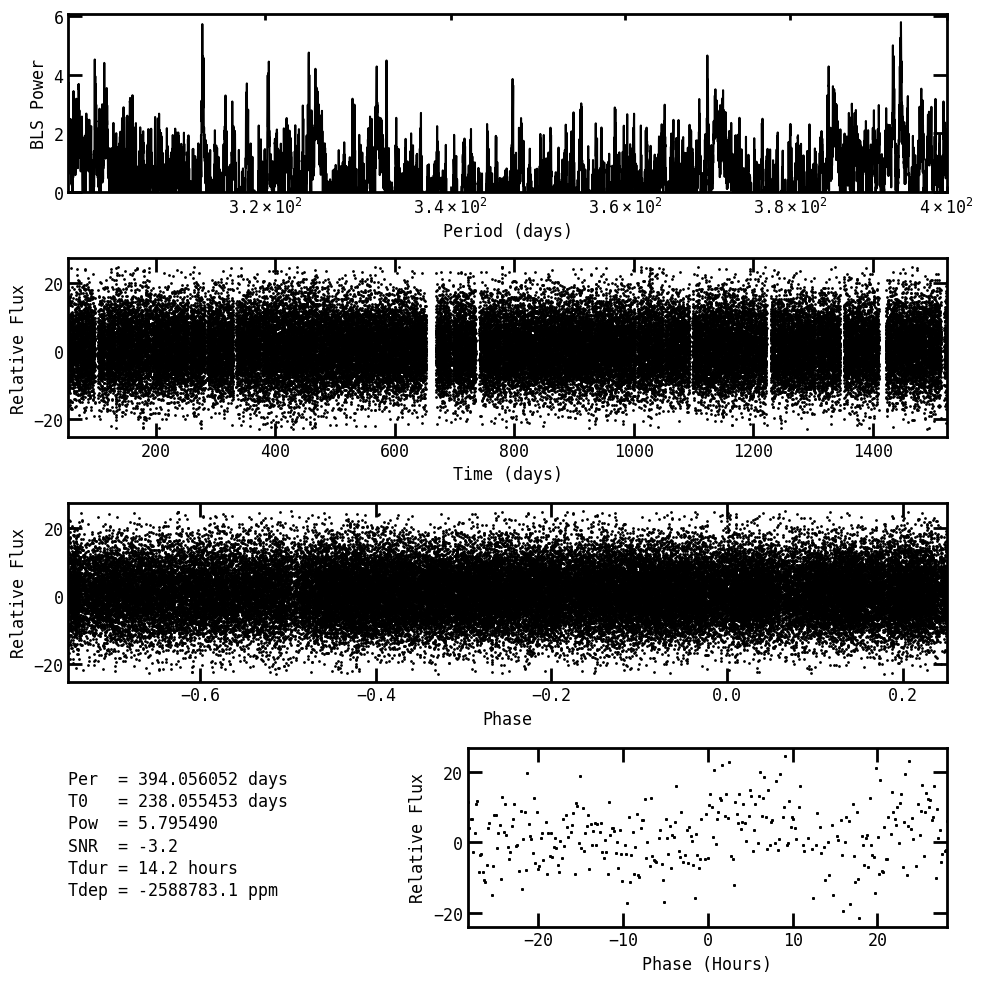

In [98]:
# Set up the BLS inputs and run
gbls_inputs          = gbls.gbls_inputs_class() # Initialize needed inputs
gbls_inputs.zerotime = 0.0
gbls_inputs.Rstar    = 1.0
gbls_inputs.Mstar    = 1.0
gbls_inputs.plots    = 1 # 1=X11, 2=both, 0=none
gbls_inputs.freq1    = 1/ 400 # 2/(np.max(phot.time) - np.min(phot.time))
gbls_inputs.freq2    = 1/ 300  # -1 
gbls_inputs.filename = "Kepler Test"  # Used for naming the file, extension replaced with PNG.

# Run BLS, applying data cuts
gbls_ans = gbls.bls(gbls_inputs, phot.time[(phot.icut==0) & (med_cut==0)], \
                                 phot.flux_f[(phot.icut==0) & (med_cut==0)])

In [96]:
per = 384.84774501
t0 = 632.828067
phase = (phot.time - t0) / per - np.floor( (phot.time -t0) / per)
phase[phase > 0.5] -= 1.0
phase_hours = phase*per*24

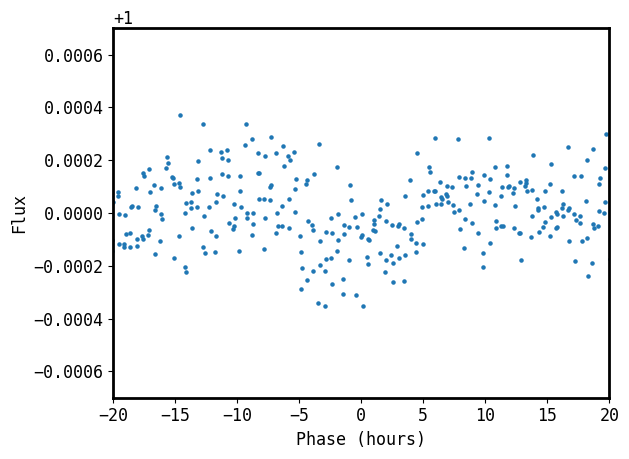

In [97]:
med_flux = np.median(phot.flux_f[(phot.icut==0) & (med_cut==0)])
plt.scatter(phase_hours[(phot.icut==0) & (med_cut==0)], phot.flux_f[(phot.icut==0) & (med_cut==0)]/med_flux,s =5)
plt.xlim(-20.0, 20)
plt.ylim(0.9993, 1.0007)
plt.xlabel('Phase (hours)')
plt.ylabel('Flux')
plt.show()